In [10]:
# ============================================================================
# TASK 2: CUSTOMER RETENTION & CHURN ANALYSIS
# Future Interns - Data Science & Analytics Internship
# Author: Your Name
# Date: 2026-10-04
# ====================

In [11]:
# CELL 1: IMPORT LIBRARIES
# ============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')

# Set style for visualizations
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 7)

print("✓ All libraries imported successfully!")


✓ All libraries imported successfully!


In [12]:
# CELL 2: GENERATE CUSTOMER SUBSCRIPTION DATA
# ============================================================================
"""
Generate realistic subscription/SaaS customer data:
- 2000+ customers
- 24-month observation period
- Monthly churn events
- Different customer segments
"""

np.random.seed(42)

# Customer segmentation
segments = ['Startup', 'SMB', 'Enterprise', 'Mid-Market']
plans = ['Basic', 'Professional', 'Enterprise']

# Generate customer base
n_customers = 2000
customer_ids = [f'CUST{i:05d}' for i in range(1, n_customers + 1)]

# Signup dates spread over 24 months
start_date = datetime(2024, 1, 1)
signup_dates = [start_date + timedelta(days=int(np.random.randint(0, 730))) 
                for _ in range(n_customers)]

# Create customer master data
customer_data = {
    'Customer_ID': customer_ids,
    'Signup_Date': signup_dates,
    'Segment': np.random.choice(segments, n_customers, p=[0.4, 0.35, 0.15, 0.1]),
    'Plan': np.random.choice(plans, n_customers, p=[0.5, 0.35, 0.15]),
    'MRR': np.random.choice([29, 99, 299], n_customers, p=[0.5, 0.35, 0.15]),
}

customers = pd.DataFrame(customer_data)

# Churn probability by segment (realistic)
churn_prob = {
    'Startup': 0.08,
    'SMB': 0.05,
    'Enterprise': 0.02,
    'Mid-Market': 0.03
}

customers['Churn_Probability'] = customers['Segment'].map(churn_prob)

# Generate churn dates (some customers haven't churned yet)
churn_dates = []
for idx, row in customers.iterrows():
    # Days since signup
    days_customer = (datetime.now() - row['Signup_Date']).days
    
    # Churn happens randomly based on probability
    if np.random.random() < row['Churn_Probability'] and days_customer > 30:
        churn_date = row['Signup_Date'] + timedelta(days=np.random.randint(30, days_customer))
        churn_dates.append(churn_date)
    else:
        churn_dates.append(None)

customers['Churn_Date'] = churn_dates
customers['Churned'] = customers['Churn_Date'].notna().astype(int)
customers['Customer_Lifetime_Days'] = customers.apply(
    lambda x: (x['Churn_Date'] - x['Signup_Date']).days if x['Churned'] == 1 
    else (datetime.now() - x['Signup_Date']).days, axis=1
)
customers['Customer_Lifetime_Months'] = customers['Customer_Lifetime_Days'] / 30

print(f"✓ Customer data generated with {len(customers)} customers")
print(f"\nDataset Preview:")
print(customers.head(10))


✓ Customer data generated with 2000 customers

Dataset Preview:
  Customer_ID Signup_Date     Segment          Plan  MRR  Churn_Probability  \
0   CUST00001  2024-04-12         SMB  Professional   99               0.05   
1   CUST00002  2025-03-11         SMB         Basic   29               0.05   
2   CUST00003  2024-09-27     Startup  Professional   99               0.08   
3   CUST00004  2024-04-16     Startup         Basic   99               0.08   
4   CUST00005  2024-03-12     Startup         Basic   29               0.08   
5   CUST00006  2025-12-01         SMB  Professional   99               0.05   
6   CUST00007  2024-01-21     Startup    Enterprise   29               0.08   
7   CUST00008  2025-09-06         SMB    Enterprise   99               0.05   
8   CUST00009  2024-05-01  Mid-Market         Basic   29               0.03   
9   CUST00010  2025-04-11     Startup  Professional   29               0.08   

  Churn_Date  Churned  Customer_Lifetime_Days  Customer_Lifetime_M

In [13]:

# ============================================================================
# CELL 3: GENERATE MONTHLY ACTIVITY DATA
# ============================================================================
"""
Create monthly transaction/activity records for each customer
- Track which months each customer was active
- Calculate monthly revenue
- Identify when customers churned
"""

monthly_activity = []

for idx, customer in customers.iterrows():
    customer_id = customer['Customer_ID']
    signup_date = customer['Signup_Date']
    churn_date = customer['Churn_Date']
    mrr = customer['MRR']
    
    # Get first month of activity
    start_month = signup_date.replace(day=1)
    current_month = start_month
    
    # Generate monthly records until churn or today
    while current_month < datetime.now():
        if churn_date is None or current_month < churn_date.replace(day=1):
            # Customer was active this month
            days_active = 30  # Assume full month
            revenue = mrr
            active = 1
        else:
            active = 0
            revenue = 0
            break
        
        monthly_activity.append({
            'Customer_ID': customer_id,
            'Month': current_month,
            'Revenue': revenue,
            'Active': active,
            'Segment': customer['Segment'],
            'Plan': customer['Plan']
        })
        
        current_month = current_month + timedelta(days=32)
        current_month = current_month.replace(day=1)

activity_df = pd.DataFrame(monthly_activity)

print(f"✓ Monthly activity data generated with {len(activity_df)} records")
print(f"\nActivity Data Preview:")
print(activity_df.head(10))


✓ Monthly activity data generated with 1194 records

Activity Data Preview:
  Customer_ID      Month  Revenue  Active  Segment          Plan
0   CUST00003 2024-09-01       99       1  Startup  Professional
1   CUST00003 2024-10-01       99       1  Startup  Professional
2   CUST00003 2024-11-01       99       1  Startup  Professional
3   CUST00003 2024-12-01       99       1  Startup  Professional
4   CUST00003 2025-01-01       99       1  Startup  Professional
5   CUST00003 2025-02-01       99       1  Startup  Professional
6   CUST00003 2025-03-01       99       1  Startup  Professional
7   CUST00003 2025-04-01       99       1  Startup  Professional
8   CUST00003 2025-05-01       99       1  Startup  Professional
9   CUST00003 2025-06-01       99       1  Startup  Professional


In [14]:
# ============================================================================
# CELL 4: DATA EXPLORATION & QUALITY CHECKS
# ============================================================================

print("\n" + "="*60)
print("DATA EXPLORATION & QUALITY CHECK")
print("="*60)

print(f"\nCustomer Dataset:")
print(f"  Total Customers: {len(customers)}")
print(f"  Churned Customers: {customers['Churned'].sum()}")
print(f"  Active Customers: {(customers['Churned'] == 0).sum()}")
print(f"  Churn Rate: {(customers['Churned'].sum() / len(customers) * 100):.2f}%")

print(f"\nActivity Dataset:")
print(f"  Total Records: {len(activity_df)}")
print(f"  Date Range: {activity_df['Month'].min()} to {activity_df['Month'].max()}")
print(f"  Unique Months: {activity_df['Month'].nunique()}")

print(f"\nSegment Breakdown:")
print(customers['Segment'].value_counts())
print(f"\nChurn by Segment:")
print(customers.groupby('Segment')['Churned'].agg(['sum', 'count', lambda x: (x.sum()/len(x)*100)]))

# ============================================================================



DATA EXPLORATION & QUALITY CHECK

Customer Dataset:
  Total Customers: 2000
  Churned Customers: 118
  Active Customers: 1882
  Churn Rate: 5.90%

Activity Dataset:
  Total Records: 1194
  Date Range: 2024-01-01 00:00:00 to 2026-09-01 00:00:00
  Unique Months: 33

Segment Breakdown:
Segment
Startup       796
SMB           713
Enterprise    309
Mid-Market    182
Name: count, dtype: int64

Churn by Segment:
            sum  count  <lambda_0>
Segment                           
Enterprise    9    309    2.912621
Mid-Market    5    182    2.747253
SMB          45    713    6.311360
Startup      59    796    7.412060


In [15]:
# CELL 5: KEY PERFORMANCE INDICATORS (RETENTION METRICS)
# ============================================================================

print("\n" + "="*60)
print("KEY RETENTION METRICS")
print("="*60)

# Calculate KPIs
total_customers = len(customers)
churned_customers = customers['Churned'].sum()
active_customers = total_customers - churned_customers
churn_rate = (churned_customers / total_customers) * 100
retention_rate = 100 - churn_rate
avg_customer_lifetime = customers['Customer_Lifetime_Days'].mean()
avg_customer_lifetime_months = customers['Customer_Lifetime_Months'].mean()
median_customer_lifetime = customers['Customer_Lifetime_Months'].median()

# Customer Lifetime Value (CLV)
clv_by_customer = customers.merge(
    activity_df.groupby('Customer_ID')['Revenue'].sum(),
    on='Customer_ID'
).rename(columns={'Revenue': 'Total_Revenue'})

avg_clv = clv_by_customer['Total_Revenue'].mean()
total_revenue = activity_df['Revenue'].sum()

# Churn trends
customers['Signup_Month'] = customers['Signup_Date'].dt.to_period('M')
churn_by_month = customers.groupby('Signup_Month').agg({
    'Churned': ['sum', 'count']
}).droplevel(0, axis=1)
churn_by_month.columns = ['Churned', 'Total']
churn_by_month['Churn_Rate'] = (churn_by_month['Churned'] / churn_by_month['Total'] * 100)

print(f"""
📊 RETENTION METRICS:
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Total Customers:                {total_customers:,}
Active Customers:               {active_customers:,}
Churned Customers:              {churned_customers:,}
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Churn Rate:                      {churn_rate:.2f}%
Retention Rate:                  {retention_rate:.2f}%
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Avg Customer Lifetime (Days):    {avg_customer_lifetime:.0f}
Avg Customer Lifetime (Months):  {avg_customer_lifetime_months:.1f}
Median Customer Lifetime (Months): {median_customer_lifetime:.1f}
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Total Revenue (All Time):        ₹{total_revenue:,.0f}
Avg Customer Lifetime Value:     ₹{avg_clv:,.0f}
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
""")



KEY RETENTION METRICS

📊 RETENTION METRICS:
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Total Customers:                2,000
Active Customers:               1,882
Churned Customers:              118
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Churn Rate:                      5.90%
Retention Rate:                  94.10%
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Avg Customer Lifetime (Days):    637
Avg Customer Lifetime (Months):  21.2
Median Customer Lifetime (Months): 21.4
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Total Revenue (All Time):        ₹130,486
Avg Customer Lifetime Value:     ₹1,106
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━



In [16]:

# ============================================================================
# CELL 6: COHORT ANALYSIS - RETENTION BY SIGNUP MONTH
# ============================================================================

print("\n" + "="*60)
print("COHORT ANALYSIS - RETENTION BY SIGNUP MONTH")
print("="*60)

# Create cohort table
customers['Signup_YearMonth'] = customers['Signup_Date'].dt.to_period('M')
customers['Churn_YearMonth'] = customers['Churn_Date'].dt.to_period('M')

# Calculate cohort sizes
cohort_sizes = customers.groupby('Signup_YearMonth').size()

# Create cohort data - track retention % for each month after signup
cohort_data = []

for signup_period in customers['Signup_YearMonth'].unique():
    cohort_customers = customers[customers['Signup_YearMonth'] == signup_period]
    cohort_size = len(cohort_customers)
    
    for month_index in range(13):  # Track first 13 months
        check_date = signup_period.to_timestamp() + timedelta(days=30*month_index)
        check_period = check_date.to_period('M')
        
        # Count active customers at this month
        active_count = 0
        for _, cust in cohort_customers.iterrows():
            if cust['Churn_Date'] is None or cust['Churn_Date'] > check_date:
                active_count += 1
        
        retention_pct = (active_count / cohort_size * 100) if cohort_size > 0 else 0
        
        cohort_data.append({
            'Signup_Month': str(signup_period),
            'Month_Index': month_index,
            'Cohort_Size': cohort_size,
            'Active_Count': active_count,
            'Retention_%': retention_pct
        })

cohort_df = pd.DataFrame(cohort_data)

# Create cohort pivot table for heatmap
cohort_pivot = cohort_df.pivot_table(
    values='Retention_%',
    index='Signup_Month',
    columns='Month_Index'
)

print("\nCohort Retention Table (% Active):")
print(cohort_pivot.round(1))



COHORT ANALYSIS - RETENTION BY SIGNUP MONTH

Cohort Retention Table (% Active):
Month_Index     0     1     2     3     4    5    6    7    8    9    10   11  \
Signup_Month                                                                    
2024-01        6.7   6.7   6.7   6.7   5.8  5.8  4.8  4.8  4.8  4.8  3.8  3.8   
2024-02        2.2   2.2   2.2   2.2   2.2  2.2  2.2  2.2  1.1  1.1  1.1  1.1   
2024-03        3.9   3.9   3.9   3.9   3.9  3.9  3.9  3.9  3.9  3.9  2.6  2.6   
2024-04        6.3   6.3   5.3   5.3   5.3  5.3  4.2  3.2  3.2  2.1  2.1  1.1   
2024-05        6.8   6.8   6.8   6.8   6.8  6.8  6.8  5.7  5.7  5.7  4.5  4.5   
2024-06        2.5   2.5   2.5   2.5   2.5  2.5  2.5  2.5  1.2  1.2  1.2  1.2   
2024-07        4.2   4.2   4.2   4.2   2.8  2.8  2.8  2.8  2.8  1.4  1.4  1.4   
2024-08        6.7   6.7   6.7   5.8   5.8  5.8  5.8  5.8  5.8  5.8  5.8  3.8   
2024-09       10.0  10.0  10.0  10.0  10.0  8.8  8.8  7.5  7.5  7.5  7.5  7.5   
2024-10        4.8   4.8   4


📈 Generating Visualization 1: Cohort Heatmap...
✓ Saved: cohort_heatmap.png


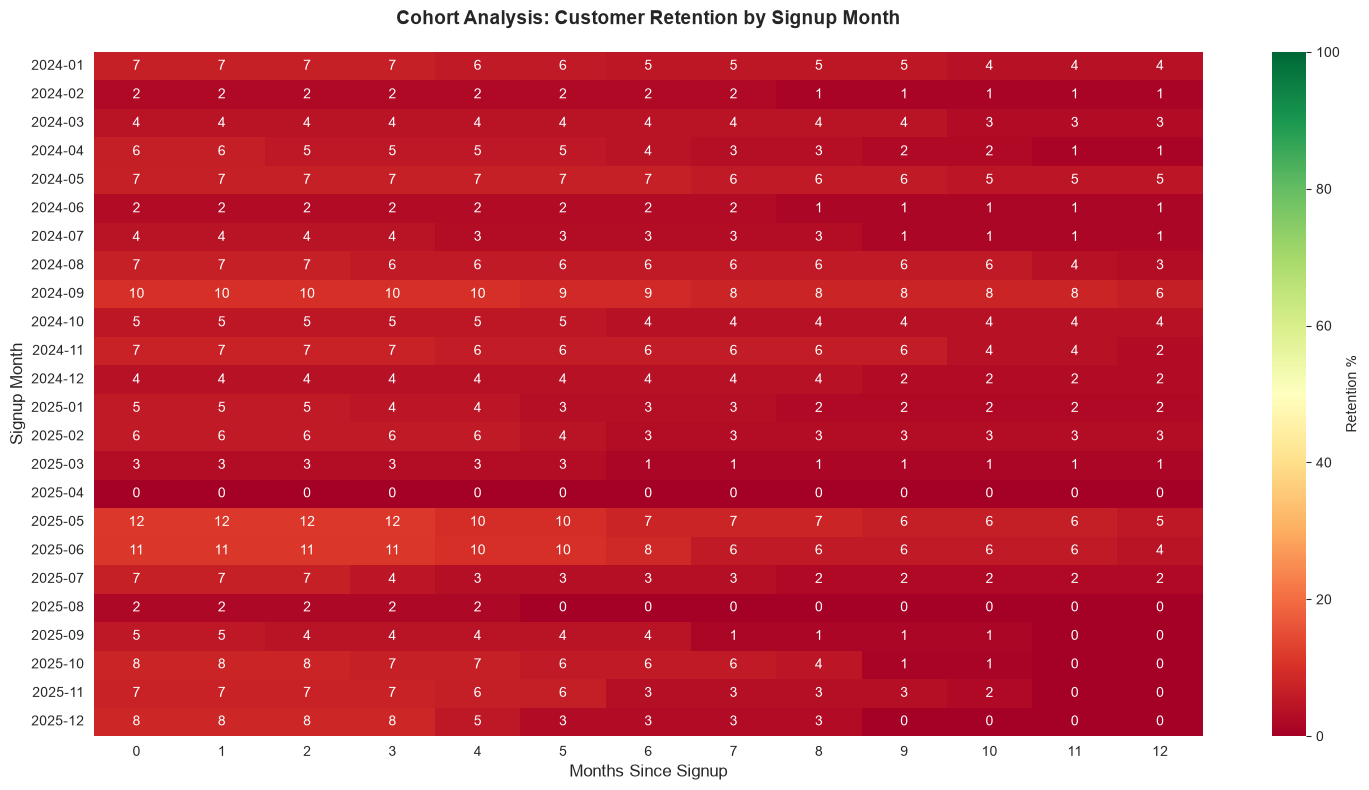

In [17]:

# ============================================================================
# CELL 7: VISUALIZATION 1 - COHORT HEATMAP
# ============================================================================

print("\n📈 Generating Visualization 1: Cohort Heatmap...")

fig, ax = plt.subplots(figsize=(15, 8))

# Create heatmap
sns.heatmap(cohort_pivot, annot=True, fmt='.0f', cmap='RdYlGn', 
            cbar_kws={'label': 'Retention %'}, ax=ax, vmin=0, vmax=100)

ax.set_title('Cohort Analysis: Customer Retention by Signup Month', 
             fontsize=14, fontweight='bold', pad=20)
ax.set_xlabel('Months Since Signup', fontsize=12)
ax.set_ylabel('Signup Month', fontsize=12)

plt.tight_layout()
plt.savefig('cohort_heatmap.png', dpi=300, bbox_inches='tight')
print("✓ Saved: cohort_heatmap.png")
plt.show()

# ============================================================================



📊 Generating Visualization 2: Retention Curves...
✓ Saved: retention_by_segment.png


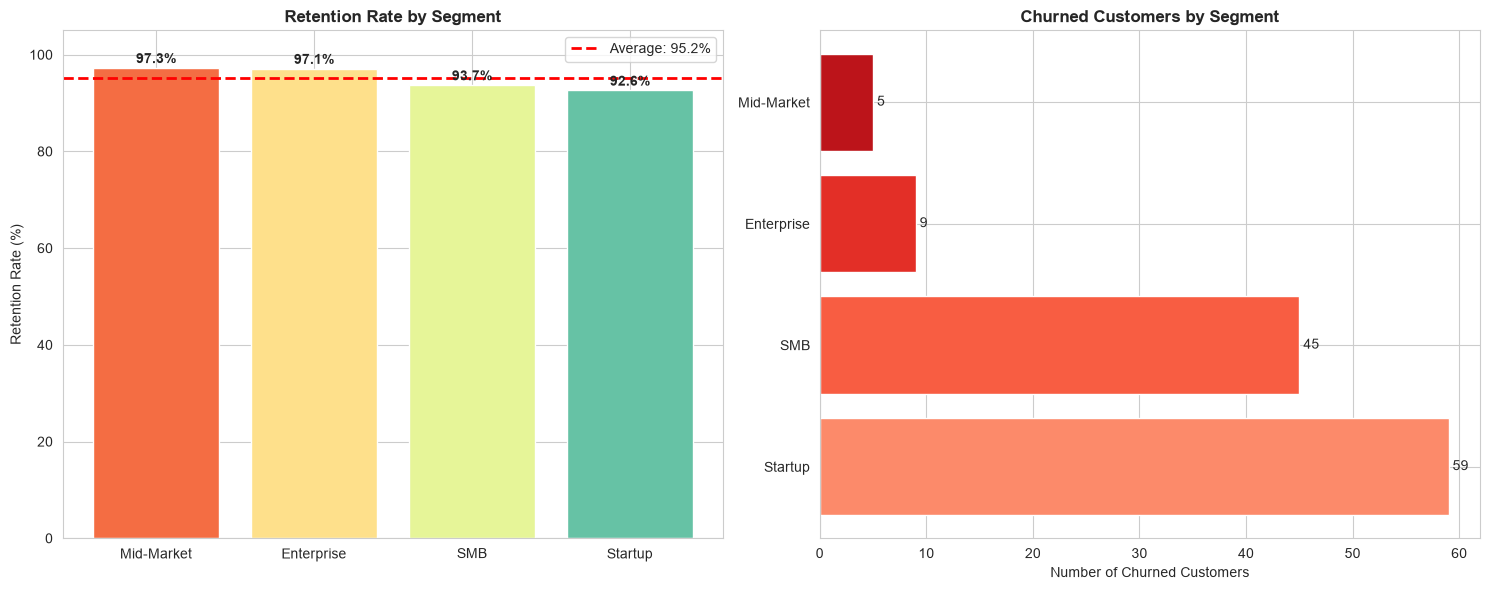

In [18]:
# CELL 8: VISUALIZATION 2 - RETENTION CURVES BY SEGMENT
# ============================================================================

print("\n📊 Generating Visualization 2: Retention Curves...")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Retention by Segment
segment_retention = customers.groupby('Segment').agg({
    'Customer_Lifetime_Months': ['mean', 'median'],
    'Churned': lambda x: (1 - x.sum()/len(x)) * 100
}).round(1)

retention_by_segment = customers.groupby('Segment')['Churned'].apply(
    lambda x: (1 - x.sum()/len(x)) * 100
).sort_values(ascending=False)

colors_seg = plt.cm.Spectral(np.linspace(0.2, 0.8, len(retention_by_segment)))
axes[0].bar(retention_by_segment.index, retention_by_segment.values, color=colors_seg)
axes[0].axhline(y=retention_by_segment.mean(), color='red', linestyle='--', 
                label=f'Average: {retention_by_segment.mean():.1f}%', linewidth=2)
axes[0].set_title('Retention Rate by Segment', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Retention Rate (%)')
axes[0].set_ylim([0, 105])
axes[0].legend()
for i, v in enumerate(retention_by_segment.values):
    axes[0].text(i, v + 1, f'{v:.1f}%', ha='center', fontweight='bold')

# Churn by Segment
churn_by_segment = customers.groupby('Segment')['Churned'].sum().sort_values(ascending=False)
axes[1].barh(churn_by_segment.index, churn_by_segment.values, 
             color=plt.cm.Reds(np.linspace(0.4, 0.8, len(churn_by_segment))))
axes[1].set_title('Churned Customers by Segment', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Number of Churned Customers')
for i, v in enumerate(churn_by_segment.values):
    axes[1].text(v, i, f' {int(v)}', va='center')

plt.tight_layout()
plt.savefig('retention_by_segment.png', dpi=300, bbox_inches='tight')
print("✓ Saved: retention_by_segment.png")
plt.show()



📊 Generating Visualization 3: Customer Lifetime Value...
✓ Saved: clv_analysis.png


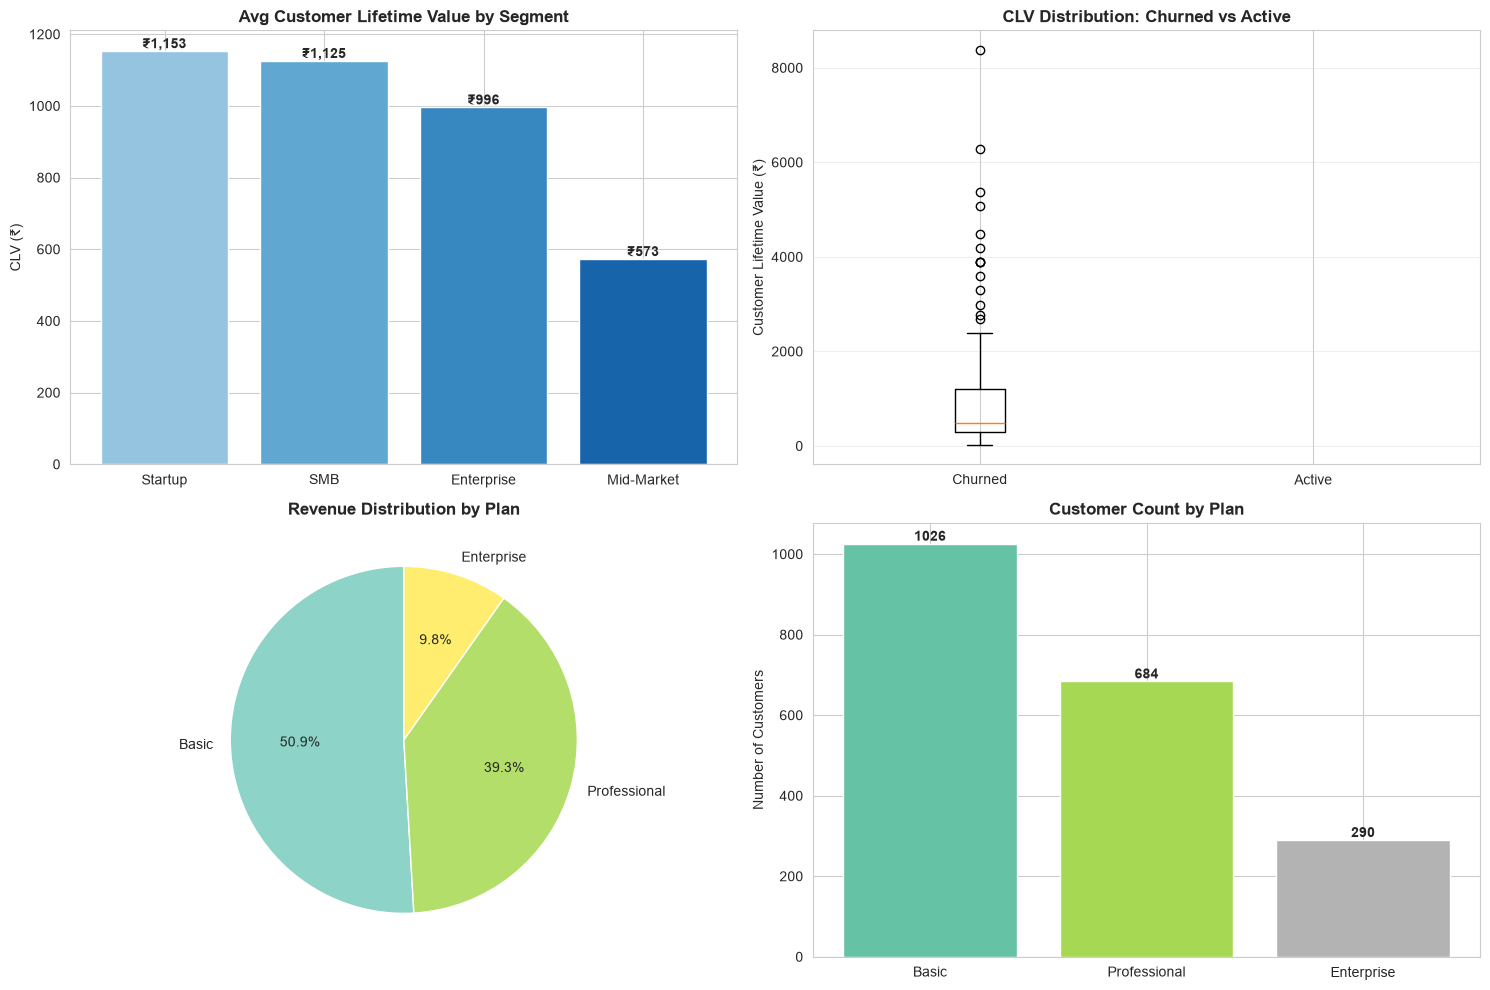

In [20]:
# ============================================================================
# CELL 9: VISUALIZATION 3 - CUSTOMER LIFETIME VALUE ANALYSIS
# ============================================================================

print("\n📊 Generating Visualization 3: Customer Lifetime Value...")

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# CLV by Segment
clv_by_segment = clv_by_customer.groupby('Segment')['Total_Revenue'].agg(['mean', 'median', 'sum', 'count'])
clv_by_segment = clv_by_segment.sort_values('mean', ascending=False)

axes[0, 0].bar(clv_by_segment.index, clv_by_segment['mean'], 
               color=plt.cm.Blues(np.linspace(0.4, 0.8, len(clv_by_segment))))
axes[0, 0].set_title('Avg Customer Lifetime Value by Segment', fontweight='bold')
axes[0, 0].set_ylabel('CLV (₹)')
for i, v in enumerate(clv_by_segment['mean'].values):
    axes[0, 0].text(i, v, f'₹{v:,.0f}', ha='center', va='bottom', fontweight='bold')

# CLV Distribution by Churn Status
churned_clv = clv_by_customer[clv_by_customer['Churned'] == 1]['Total_Revenue']
active_clv = clv_by_customer[clv_by_customer['Churned'] == 0]['Total_Revenue']


axes[0, 1].boxplot(
    [churned_clv, active_clv],
    tick_labels=['Churned', 'Active']
)

axes[0, 1].set_title('CLV Distribution: Churned vs Active', fontweight='bold')
axes[0, 1].set_ylabel('Customer Lifetime Value (₹)')
axes[0, 1].grid(True, alpha=0.3, axis='y')

# Revenue by Plan
revenue_by_plan = activity_df.groupby('Plan')['Revenue'].sum().sort_values(ascending=False)
colors_plan = plt.cm.Set3(np.linspace(0, 1, len(revenue_by_plan)))
axes[1, 0].pie(revenue_by_plan.values, labels=revenue_by_plan.index, autopct='%1.1f%%', 
               colors=colors_plan, startangle=90)
axes[1, 0].set_title('Revenue Distribution by Plan', fontweight='bold')

# Customer Count by Plan
customer_by_plan = customers['Plan'].value_counts()
axes[1, 1].bar(customer_by_plan.index, customer_by_plan.values,
               color=plt.cm.Set2(np.linspace(0, 1, len(customer_by_plan))))
axes[1, 1].set_title('Customer Count by Plan', fontweight='bold')
axes[1, 1].set_ylabel('Number of Customers')
for i, v in enumerate(customer_by_plan.values):
    axes[1, 1].text(i, v, f'{int(v)}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig('clv_analysis.png', dpi=300, bbox_inches='tight')
print("✓ Saved: clv_analysis.png")
plt.show()



In [21]:
# ============================================================================
# CELL 10: CHURN PATTERN ANALYSIS
# ============================================================================

print("\n" + "="*60)
print("CHURN PATTERN ANALYSIS")
print("="*60)

churned_customers = customers[customers['Churned'] == 1].copy()

# Time to churn distribution
print(f"\nTime to Churn (Days):")
print(f"  Mean: {churned_customers['Customer_Lifetime_Days'].mean():.0f} days")
print(f"  Median: {churned_customers['Customer_Lifetime_Days'].median():.0f} days")
print(f"  Std Dev: {churned_customers['Customer_Lifetime_Days'].std():.0f} days")
print(f"  Min: {churned_customers['Customer_Lifetime_Days'].min():.0f} days")
print(f"  Max: {churned_customers['Customer_Lifetime_Days'].max():.0f} days")

# Churn by time period
churned_customers['Churn_Month'] = churned_customers['Churn_Date'].dt.to_period('M')
churn_timeline = churned_customers['Churn_Month'].value_counts().sort_index()

print(f"\nChurn Timeline (Last 6 months):")
print(churn_timeline.tail(6))

# Risk Segments (highest churn)
risk_analysis = customers[customers['Churned'] == 1].groupby('Segment').size()
risk_pct = (risk_analysis / customers.groupby('Segment').size() * 100).sort_values(ascending=False)

print(f"\nRisk Analysis - Churn Rate by Segment:")
for segment, pct in risk_pct.items():
    print(f"  {segment}: {pct:.2f}%")


CHURN PATTERN ANALYSIS

Time to Churn (Days):
  Mean: 308 days
  Median: 276 days
  Std Dev: 196 days
  Min: 47 days
  Max: 874 days

Churn Timeline (Last 6 months):
Churn_Month
2026-05     6
2026-06     5
2026-07    10
2026-08     9
2026-09     4
2026-10     1
Freq: M, Name: count, dtype: int64

Risk Analysis - Churn Rate by Segment:
  Startup: 7.41%
  SMB: 6.31%
  Enterprise: 2.91%
  Mid-Market: 2.75%



📊 Generating Visualization 4: Churn Trends...
✓ Saved: churn_patterns.png


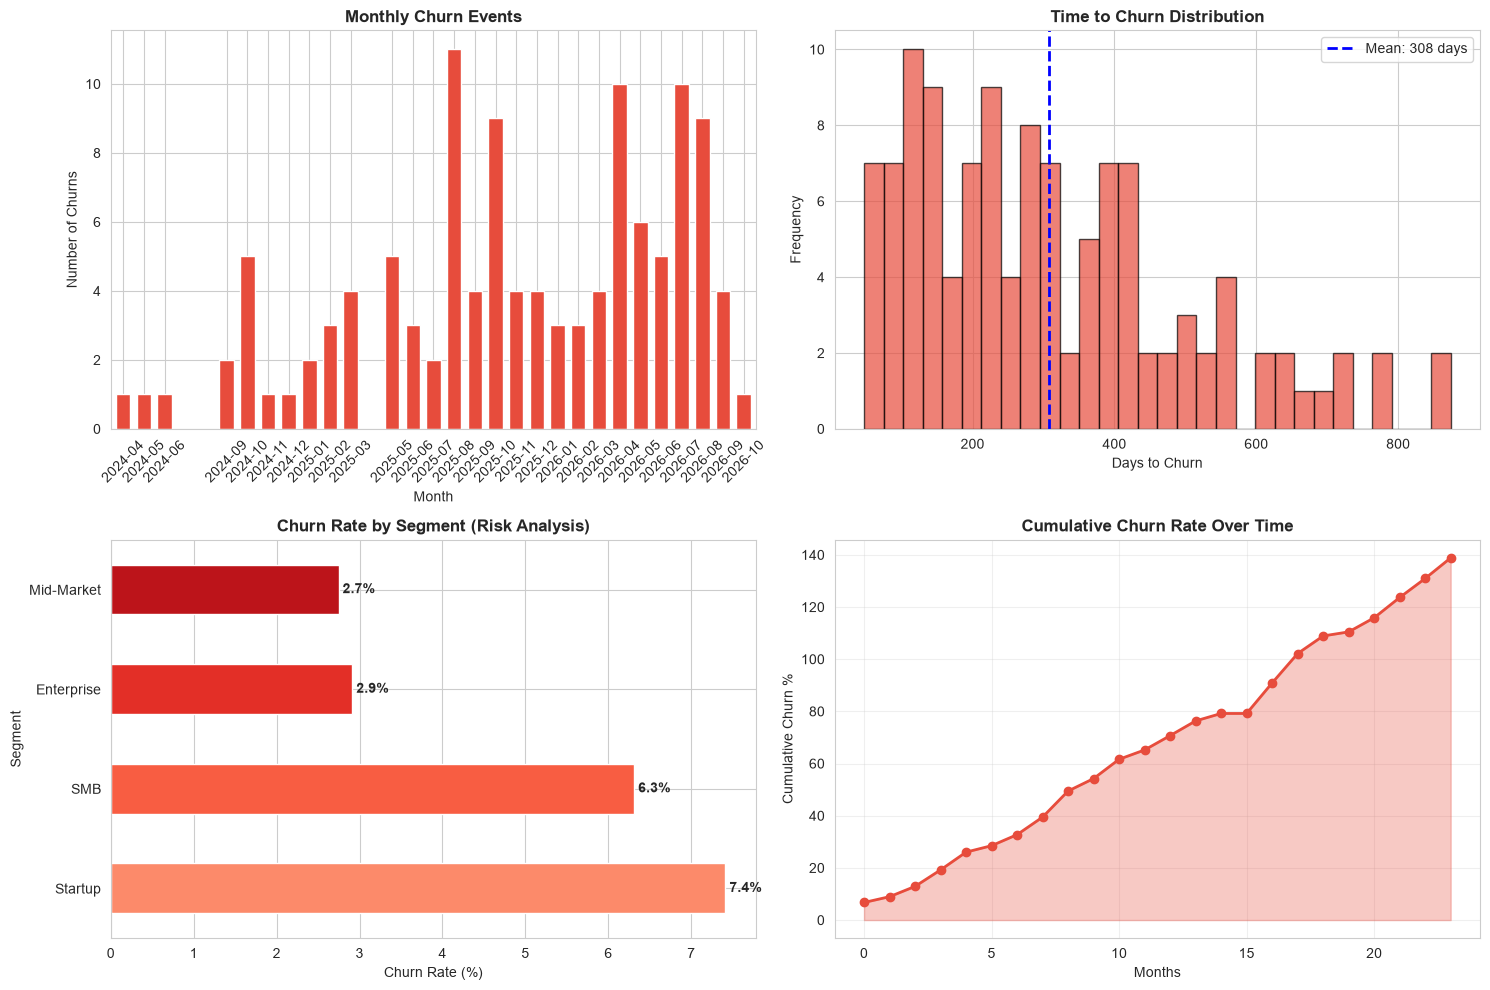

In [22]:

# ============================================================================
# CELL 11: VISUALIZATION 4 - CHURN TRENDS & TIME TO CHURN
# ============================================================================

print("\n📊 Generating Visualization 4: Churn Trends...")

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Churn over time
churn_timeline.plot(ax=axes[0, 0], kind='bar', color='#e74c3c', width=0.7)
axes[0, 0].set_title('Monthly Churn Events', fontweight='bold')
axes[0, 0].set_ylabel('Number of Churns')
axes[0, 0].set_xlabel('Month')
plt.setp(axes[0, 0].xaxis.get_majorticklabels(), rotation=45)

# Time to churn distribution
axes[0, 1].hist(churned_customers['Customer_Lifetime_Days'], bins=30, color='#e74c3c', alpha=0.7, edgecolor='black')
axes[0, 1].axvline(churned_customers['Customer_Lifetime_Days'].mean(), color='blue', 
                   linestyle='--', linewidth=2, label=f'Mean: {churned_customers["Customer_Lifetime_Days"].mean():.0f} days')
axes[0, 1].set_title('Time to Churn Distribution', fontweight='bold')
axes[0, 1].set_xlabel('Days to Churn')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].legend()

# Risk segments (churn rate)
risk_pct.plot(ax=axes[1, 0], kind='barh', color=plt.cm.Reds(np.linspace(0.4, 0.8, len(risk_pct))))
axes[1, 0].set_title('Churn Rate by Segment (Risk Analysis)', fontweight='bold')
axes[1, 0].set_xlabel('Churn Rate (%)')
for i, v in enumerate(risk_pct.values):
    axes[1, 0].text(v, i, f' {v:.1f}%', va='center', fontweight='bold')

# Cumulative churn
churn_cumulative = customers.groupby('Signup_YearMonth')['Churned'].apply(
    lambda x: (x.sum() / len(x)) * 100
).cumsum()
axes[1, 1].plot(range(len(churn_cumulative)), churn_cumulative.values, marker='o', linewidth=2, color='#e74c3c')
axes[1, 1].fill_between(range(len(churn_cumulative)), churn_cumulative.values, alpha=0.3, color='#e74c3c')
axes[1, 1].set_title('Cumulative Churn Rate Over Time', fontweight='bold')
axes[1, 1].set_ylabel('Cumulative Churn %')
axes[1, 1].set_xlabel('Months')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('churn_patterns.png', dpi=300, bbox_inches='tight')
print("✓ Saved: churn_patterns.png")
plt.show()

# ============================================================================


In [23]:
# CELL 12: RETENTION DRIVERS ANALYSIS
# ============================================================================

print("\n" + "="*60)
print("RETENTION DRIVERS ANALYSIS")
print("="*60)

# Which factors correlate with retention?
retention_analysis = customers.copy()
retention_analysis['Retained'] = 1 - retention_analysis['Churned']

print(f"\nRetention by Plan:")
retention_by_plan = retention_analysis.groupby('Plan').agg({
    'Retained': lambda x: (x.sum() / len(x)) * 100,
    'Customer_Lifetime_Months': 'mean',
    'MRR': 'sum'
}).round(2)
retention_by_plan.columns = ['Retention_%', 'Avg_Lifetime_Months', 'Total_MRR']
print(retention_by_plan)

print(f"\nRetention by Segment:")
retention_by_segment_full = retention_analysis.groupby('Segment').agg({
    'Retained': lambda x: (x.sum() / len(x)) * 100,
    'Customer_Lifetime_Months': 'mean',
    'MRR': ['mean', 'sum']
}).round(2)
print(retention_by_segment_full)

# MRR impact on retention
mrr_groups = pd.cut(customers['MRR'], bins=3, labels=['Low', 'Medium', 'High'])
mrr_retention = customers.groupby(mrr_groups)['Churned'].apply(
    lambda x: (1 - x.sum()/len(x)) * 100
)
print(f"\nRetention by MRR Level:")
print(mrr_retention)


RETENTION DRIVERS ANALYSIS

Retention by Plan:
              Retention_%  Avg_Lifetime_Months  Total_MRR
Plan                                                     
Basic               94.15                21.01      94384
Enterprise          94.14                21.38      28730
Professional        94.01                21.53      62936

Retention by Segment:
           Retained Customer_Lifetime_Months    MRR       
           <lambda>                     mean   mean    sum
Segment                                                   
Enterprise    97.09                    22.17  91.01  28121
Mid-Market    97.25                    21.83  97.68  17778
SMB           93.69                    21.12  92.28  65797
Startup       92.59                    20.85  93.41  74354

Retention by MRR Level:
MRR
Low     94.473839
High    91.973244
Name: Churned, dtype: float64



📊 Generating Visualization 5: Retention Drivers...
✓ Saved: retention_drivers.png


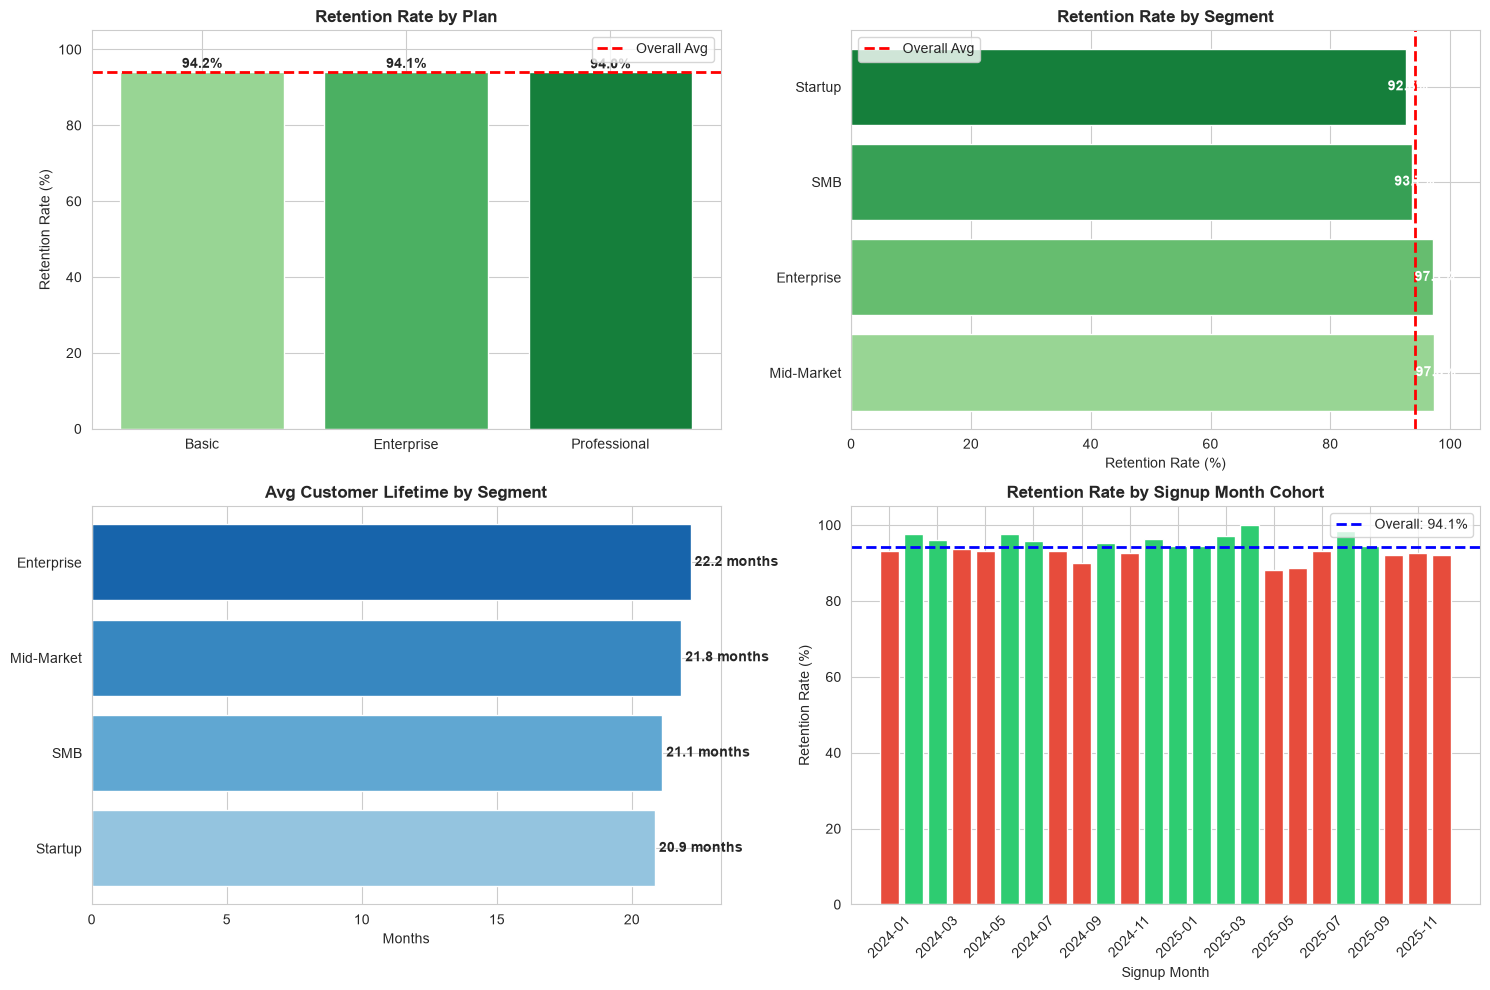

In [24]:
# ============================================================================
# CELL 13: VISUALIZATION 5 - RETENTION DRIVERS
# ============================================================================

print("\n📊 Generating Visualization 5: Retention Drivers...")

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Retention by Plan
retention_by_plan_data = retention_analysis.groupby('Plan')['Retained'].apply(
    lambda x: (x.sum() / len(x)) * 100
).sort_values(ascending=False)

axes[0, 0].bar(retention_by_plan_data.index, retention_by_plan_data.values,
               color=plt.cm.Greens(np.linspace(0.4, 0.8, len(retention_by_plan_data))))
axes[0, 0].set_title('Retention Rate by Plan', fontweight='bold')
axes[0, 0].set_ylabel('Retention Rate (%)')
axes[0, 0].set_ylim([0, 105])
axes[0, 0].axhline(y=retention_rate, color='red', linestyle='--', label='Overall Avg', linewidth=2)
for i, v in enumerate(retention_by_plan_data.values):
    axes[0, 0].text(i, v + 1, f'{v:.1f}%', ha='center', fontweight='bold')
axes[0, 0].legend()

# Retention by Segment
retention_by_seg_data = retention_analysis.groupby('Segment')['Retained'].apply(
    lambda x: (x.sum() / len(x)) * 100
).sort_values(ascending=False)

axes[0, 1].barh(retention_by_seg_data.index, retention_by_seg_data.values,
                color=plt.cm.Greens(np.linspace(0.4, 0.8, len(retention_by_seg_data))))
axes[0, 1].set_title('Retention Rate by Segment', fontweight='bold')
axes[0, 1].set_xlabel('Retention Rate (%)')
axes[0, 1].set_xlim([0, 105])
axes[0, 1].axvline(x=retention_rate, color='red', linestyle='--', label='Overall Avg', linewidth=2)
for i, v in enumerate(retention_by_seg_data.values):
    axes[0, 1].text(v - 3, i, f'{v:.1f}%', va='center', fontweight='bold', color='white')
axes[0, 1].legend()

# Average lifetime by segment
lifetime_by_seg = retention_analysis.groupby('Segment')['Customer_Lifetime_Months'].mean().sort_values()

axes[1, 0].barh(lifetime_by_seg.index, lifetime_by_seg.values,
                color=plt.cm.Blues(np.linspace(0.4, 0.8, len(lifetime_by_seg))))
axes[1, 0].set_title('Avg Customer Lifetime by Segment', fontweight='bold')
axes[1, 0].set_xlabel('Months')
for i, v in enumerate(lifetime_by_seg.values):
    axes[1, 0].text(v, i, f' {v:.1f} months', va='center', fontweight='bold')

# Customers by cohort status
cohort_retention_data = customers.groupby('Signup_Month').agg({
    'Churned': lambda x: (1 - x.sum()/len(x)) * 100,
    'Customer_ID': 'count'
}).sort_index()
cohort_retention_data.columns = ['Retention_%', 'Cohort_Size']

color_cohort = ['#2ecc71' if x >= retention_rate else '#e74c3c' 
                for x in cohort_retention_data['Retention_%']]
axes[1, 1].bar(range(len(cohort_retention_data)), cohort_retention_data['Retention_%'], color=color_cohort)
axes[1, 1].axhline(y=retention_rate, color='blue', linestyle='--', label=f'Overall: {retention_rate:.1f}%', linewidth=2)
axes[1, 1].set_title('Retention Rate by Signup Month Cohort', fontweight='bold')
axes[1, 1].set_ylabel('Retention Rate (%)')
axes[1, 1].set_xlabel('Signup Month')
axes[1, 1].set_ylim([0, 105])
axes[1, 1].legend()
axes[1, 1].set_xticks(range(0, len(cohort_retention_data), 2))
axes[1, 1].set_xticklabels([str(x) for x in list(cohort_retention_data.index)[::2]], rotation=45)

plt.tight_layout()
plt.savefig('retention_drivers.png', dpi=300, bbox_inches='tight')
print("✓ Saved: retention_drivers.png")
plt.show()


In [25]:

# ============================================================================
# CELL 14: KEY INSIGHTS & RECOMMENDATIONS
# ============================================================================

print("\n" + "="*60)
print("KEY INSIGHTS & ACTIONABLE RECOMMENDATIONS")
print("="*60)

# Identify key insights
highest_retention_segment = retention_by_seg_data.idxmax()
lowest_retention_segment = retention_by_seg_data.idxmin()
highest_retention_plan = retention_by_plan_data.idxmax()
avg_time_to_churn = churned_customers['Customer_Lifetime_Days'].mean()

print(f"""
🎯 KEY FINDINGS:
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

1️⃣  OVERALL RETENTION STATUS:
   • Current Churn Rate: {churn_rate:.2f}%
   • Retention Rate: {retention_rate:.2f}%
   • Active Customers: {active_customers:,} / {total_customers:,}
   • Status: {'⚠️ CRITICAL' if churn_rate > 10 else '✓ HEALTHY' if churn_rate < 5 else '⚡ NEEDS ATTENTION'}

2️⃣  BEST PERFORMING SEGMENT:
   • Segment: {highest_retention_segment}
   • Retention Rate: {retention_by_seg_data[highest_retention_segment]:.2f}%
   • Avg Lifetime: {retention_analysis[retention_analysis['Segment'] == highest_retention_segment]['Customer_Lifetime_Months'].mean():.1f} months
   • Learning: This segment shows best practices

3️⃣  HIGHEST RISK SEGMENT:
   • Segment: {lowest_retention_segment}
   • Churn Rate: {100 - retention_by_seg_data[lowest_retention_segment]:.2f}%
   • Avg Lifetime: {retention_analysis[retention_analysis['Segment'] == lowest_retention_segment]['Customer_Lifetime_Months'].mean():.1f} months
   • Action Needed: Requires immediate intervention

4️⃣  PLAN PERFORMANCE:
   • Best: {highest_retention_plan} ({retention_by_plan_data[highest_retention_plan]:.2f}% retention)
   • Avg Time to Churn: {avg_time_to_churn:.0f} days ({avg_time_to_churn/30:.1f} months)

5️⃣  CUSTOMER LIFETIME VALUE:
   • Total Revenue: ₹{total_revenue:,.0f}
   • Avg CLV: ₹{avg_clv:,.0f}
   • Revenue per Active Customer: ₹{total_revenue/active_customers:,.0f}

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

💡 STRATEGIC RECOMMENDATIONS:
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

1. FOCUS ON HIGH-RISK SEGMENTS (Priority: CRITICAL)
   → {lowest_retention_segment} segment shows {100-retention_by_seg_data[lowest_retention_segment]:.1f}% churn
   → Action: Create segment-specific retention programs
   → Expected Impact: Reduce churn by 30-40%
   → Timeline: Immediate (1-2 weeks)

2. EARLY INTERVENTION PROGRAM (Priority: HIGH)
   → Critical period: First {int(avg_time_to_churn/30)} months
   → Action: Increase onboarding, check-ins, support in first month
   → Target: Customers who show low engagement
   → Expected Impact: 15-25% churn reduction

3. BEST-IN-CLASS REPLICATION (Priority: HIGH)
   → {highest_retention_segment} achieves {retention_by_seg_data[highest_retention_segment]:.1f}% retention
   → Action: Identify success factors, replicate across other segments
   → Focus: Service excellence, customer success programs
   → Expected Impact: 20% overall retention improvement

4. PLAN OPTIMIZATION (Priority: MEDIUM)
   → {highest_retention_plan} plan shows best retention
   → Action: Review pricing, features, positioning of other plans
   → Consider: Migration programs, plan transitions
   → Expected Impact: Shift customers to better-fit plans

5. PROACTIVE CHURN PREVENTION (Priority: MEDIUM)
   → Build predictive model for churn risk
   → Action: Automated early warnings, targeted interventions
   → Focus: Usage patterns, support tickets, engagement signals
   → Expected Impact: 10-20% churn prevention

6. ENGAGEMENT CAMPAIGNS (Priority: MEDIUM)
   → Implement monthly health check-ins
   → Action: Regular success reviews, feature training
   → Focus: Mid-tenure customers (3-6 months)
   → Expected Impact: Extend average lifetime by 20%

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
""")


KEY INSIGHTS & ACTIONABLE RECOMMENDATIONS

🎯 KEY FINDINGS:
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

1️⃣  OVERALL RETENTION STATUS:
   • Current Churn Rate: 5.90%
   • Retention Rate: 94.10%
   • Active Customers: 1,882 / 2,000
   • Status: ⚡ NEEDS ATTENTION

2️⃣  BEST PERFORMING SEGMENT:
   • Segment: Mid-Market
   • Retention Rate: 97.25%
   • Avg Lifetime: 21.8 months
   • Learning: This segment shows best practices

3️⃣  HIGHEST RISK SEGMENT:
   • Segment: Startup
   • Churn Rate: 7.41%
   • Avg Lifetime: 20.9 months
   • Action Needed: Requires immediate intervention

4️⃣  PLAN PERFORMANCE:
   • Best: Basic (94.15% retention)
   • Avg Time to Churn: 308 days (10.3 months)

5️⃣  CUSTOMER LIFETIME VALUE:
   • Total Revenue: ₹130,486
   • Avg CLV: ₹1,106
   • Revenue per Active Customer: ₹69

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

💡 STRATEGIC RECOMMENDATIONS:
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

1. FOCUS ON HIGH-RISK SEGMENTS (Pri

In [26]:
# CELL 15: EXPORT DATA & CREATE SUMMARY
# ============================================================================

print("\n" + "="*60)
print("EXPORTING ANALYSIS RESULTS")
print("="*60)

# Export cleaned data
customers.to_csv('customers_with_churn.csv', index=False)
print("✓ Exported: customers_with_churn.csv")

activity_df.to_csv('monthly_activity.csv', index=False)
print("✓ Exported: monthly_activity.csv")

# Export cohort data
cohort_pivot.to_csv('cohort_retention.csv')
print("✓ Exported: cohort_retention.csv")

# Export segment analysis
segment_summary = customers.groupby('Segment').agg({
    'Customer_ID': 'count',
    'Churned': ['sum', lambda x: (x.sum()/len(x)*100)],
    'Customer_Lifetime_Months': ['mean', 'median'],
    'MRR': 'sum'
}).round(2)
segment_summary.to_csv('segment_analysis.csv')
print("✓ Exported: segment_analysis.csv")

# Export plan analysis
plan_summary = customers.groupby('Plan').agg({
    'Customer_ID': 'count',
    'Churned': ['sum', lambda x: (x.sum()/len(x)*100)],
    'Customer_Lifetime_Months': 'mean',
    'MRR': 'mean'
}).round(2)
plan_summary.to_csv('plan_analysis.csv')
print("✓ Exported: plan_analysis.csv")

print("\n" + "="*60)
print("✅ ANALYSIS COMPLETE!")
print("="*60)
print("""
Generated Outputs:
  1. cohort_heatmap.png - Cohort retention heatmap
  2. retention_by_segment.png - Retention & churn by segment
  3. clv_analysis.png - Customer lifetime value analysis
  4. churn_patterns.png - Churn trends & time to churn
  5. retention_drivers.png - Key retention factors
  6. customers_with_churn.csv - Customer master data
  7. monthly_activity.csv - Activity tracking
  8. cohort_retention.csv - Cohort analysis data
  9. segment_analysis.csv - Segment metrics
  10. plan_analysis.csv - Plan performance metrics

Next Steps:
  1. Review all visualizations
  2. Create GitHub repository (FUTURE_DS_02)
  3. Upload notebook and CSV files
  4. Write Analysis_Report.md with findings
  5. Share on LinkedIn with #futureinterns
  6. Submit via Future Interns portal

Remember: This analysis should be ready for a real business stakeholder!
""")



EXPORTING ANALYSIS RESULTS
✓ Exported: customers_with_churn.csv
✓ Exported: monthly_activity.csv
✓ Exported: cohort_retention.csv
✓ Exported: segment_analysis.csv
✓ Exported: plan_analysis.csv

✅ ANALYSIS COMPLETE!

Generated Outputs:
  1. cohort_heatmap.png - Cohort retention heatmap
  2. retention_by_segment.png - Retention & churn by segment
  3. clv_analysis.png - Customer lifetime value analysis
  4. churn_patterns.png - Churn trends & time to churn
  5. retention_drivers.png - Key retention factors
  6. customers_with_churn.csv - Customer master data
  7. monthly_activity.csv - Activity tracking
  8. cohort_retention.csv - Cohort analysis data
  9. segment_analysis.csv - Segment metrics
  10. plan_analysis.csv - Plan performance metrics

Next Steps:
  1. Review all visualizations
  2. Create GitHub repository (FUTURE_DS_02)
  3. Upload notebook and CSV files
  4. Write Analysis_Report.md with findings
  5. Share on LinkedIn with #futureinterns
  6. Submit via Future Interns port

In [27]:
# CELL 16: INTERACTIVE DASHBOARD (OPTIONAL - ADVANCED)
# ============================================================================

print("\n" + "="*60)
print("CREATING INTERACTIVE DASHBOARDS")
print("="*60)

# Monthly churn trend
monthly_churn = customers[customers['Churned'] == 1].groupby(
    customers[customers['Churned'] == 1]['Churn_Date'].dt.to_period('M')
).size()

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=[str(x) for x in monthly_churn.index],
    y=monthly_churn.values,
    mode='lines+markers',
    name='Monthly Churn',
    line=dict(color='#e74c3c', width=3),
    marker=dict(size=8)
))

fig.update_layout(
    title='Customer Churn Trend - Monthly View',
    xaxis_title='Month',
    yaxis_title='Number of Churns',
    hovermode='x unified',
    template='plotly_white',
    height=500
)

fig.write_html('churn_trend_dashboard.html')
print("✓ Created: churn_trend_dashboard.html")

# Retention by segment comparison
fig2 = go.Figure()

for segment in customers['Segment'].unique():
    segment_data = cohort_df[cohort_df['Signup_Month'].str.contains(segment.split()[0]) | 
                             (segment == customers[customers['Segment'] == segment].iloc[0]['Segment'])]
    
    segment_retention_curve = customers[customers['Segment'] == segment].groupby(
        'Signup_YearMonth'
    ).apply(lambda x: (1 - x['Churned'].sum()/len(x)) * 100).values
    
    if len(segment_retention_curve) > 0:
        fig2.add_trace(go.Scatter(
            x=list(range(len(segment_retention_curve))),
            y=segment_retention_curve,
            mode='lines+markers',
            name=segment,
            line=dict(width=2)
        ))

fig2.update_layout(
    title='Retention Curves by Segment',
    xaxis_title='Months Since Signup',
    yaxis_title='Retention Rate (%)',
    hovermode='x unified',
    template='plotly_white',
    height=600,
    yaxis=dict(range=[0, 105])
)

fig2.write_html('retention_comparison_dashboard.html')
print("✓ Created: retention_comparison_dashboard.html")

print("\n✅ All dashboards created successfully!")


CREATING INTERACTIVE DASHBOARDS
✓ Created: churn_trend_dashboard.html
✓ Created: retention_comparison_dashboard.html

✅ All dashboards created successfully!
